# 2 · Guía de trabajo en equipo — Histogramas y forma de la distribución


> **¿Dónde estamos en el flujo del EDA?**
> En los notebooks 0 y 1 conocimos los datos, medimos los faltantes y calculamos estadística descriptiva (pasos 02, 04 y el comienzo del 05).
> Ahora seguimos en el paso **05 – Explorar y analizar**, pero con **gráficos**: vamos a ver **cómo se distribuye** cada variable.
> Teoría relacionada: láminas *"Histogramas: cómo se distribuyen los datos"* y *"Distribuciones simétricas y asimétricas"*.

> **Pregunta guía del análisis (la misma de los notebooks 0 y 1):**
> ¿Qué características de las células parecen diferenciar un tumor **maligno** (`target = 0`) de uno **benigno** (`target = 1`)?

> **Cómo trabajar **
> 1. Hagan una copia del notebook (*Archivo → Guardar una copia en Drive*) y suban `sample_dataset.csv` al panel **Archivos** (ícono de carpeta, a la izquierda).
> 2. Ejecuten las celdas **en orden** (Shift + Enter).
> 3. Lean los cuadros 📘, completen las celdas 🧩 (reemplazar cada `COMPLETAR`) y respondan en las celdas ✍️.
>    Las celdas 🧩 **dan error hasta que reemplacen `COMPLETAR`**: es esperable, no es un problema del notebook.
> 4. Al final, armen la sección 🎤: **cada equipo va a explicar su notebook al resto del curso en 5 minutos.**
>
> | Ícono | Significa |
> |---|---|
> | 📘 | Concepto (relacionado con la teoría vista) |
> | 💻 | Código listo para ejecutar y observar |
> | 🧩 | Código para completar (reemplazar `COMPLETAR`) |
> | ✍️ | Pregunta para responder en equipo |
> | ⭐ | Extra, solo si les sobra tiempo |
> | 🎤 | Lo que van a presentar al resto |

## 0) Preparación. Importamos librerías necesarias y conjunto de datos

In [3]:
import pandas as pd
import numpy as np                 # numpy: cálculos numéricos (lo usamos para la regla de Rice)
import matplotlib.pyplot as plt    # matplotlib: la librería de gráficos que pandas usa por detrás

In [4]:
# Cada notebook es independiente: hay que volver a importar librerías y cargar los datos.
# Si aparece FileNotFoundError: el CSV no está subido en el panel "Archivos" de ESTE notebook.
df = pd.read_csv("sample_dataset.csv")
df.shape   # esperamos (569, 31)

(569, 31)

## 1) ¿Qué es un histograma?

📘 **Concepto.** Un histograma muestra la **distribución** de una variable **numérica**:

- Agrupa los valores en **intervalos de igual amplitud** (llamados *bins*).
- La **altura de cada barra** es la **frecuencia**: cuántas observaciones caen en ese intervalo.
- Eje X → los valores de la variable. Eje Y → cuántas filas hay en cada intervalo.

Con un histograma podemos ver de un vistazo: dónde se **concentran** los datos, qué tan **dispersos** están, si la distribución es **simétrica o tiene cola**, y si hay **valores atípicos** (barras aisladas lejos del resto).

> A diferencia de un gráfico de barras, en un histograma las barras van **pegadas**: el eje X es continuo.

💻 **Vista panorámica:** un histograma por cada variable numérica del dataset.

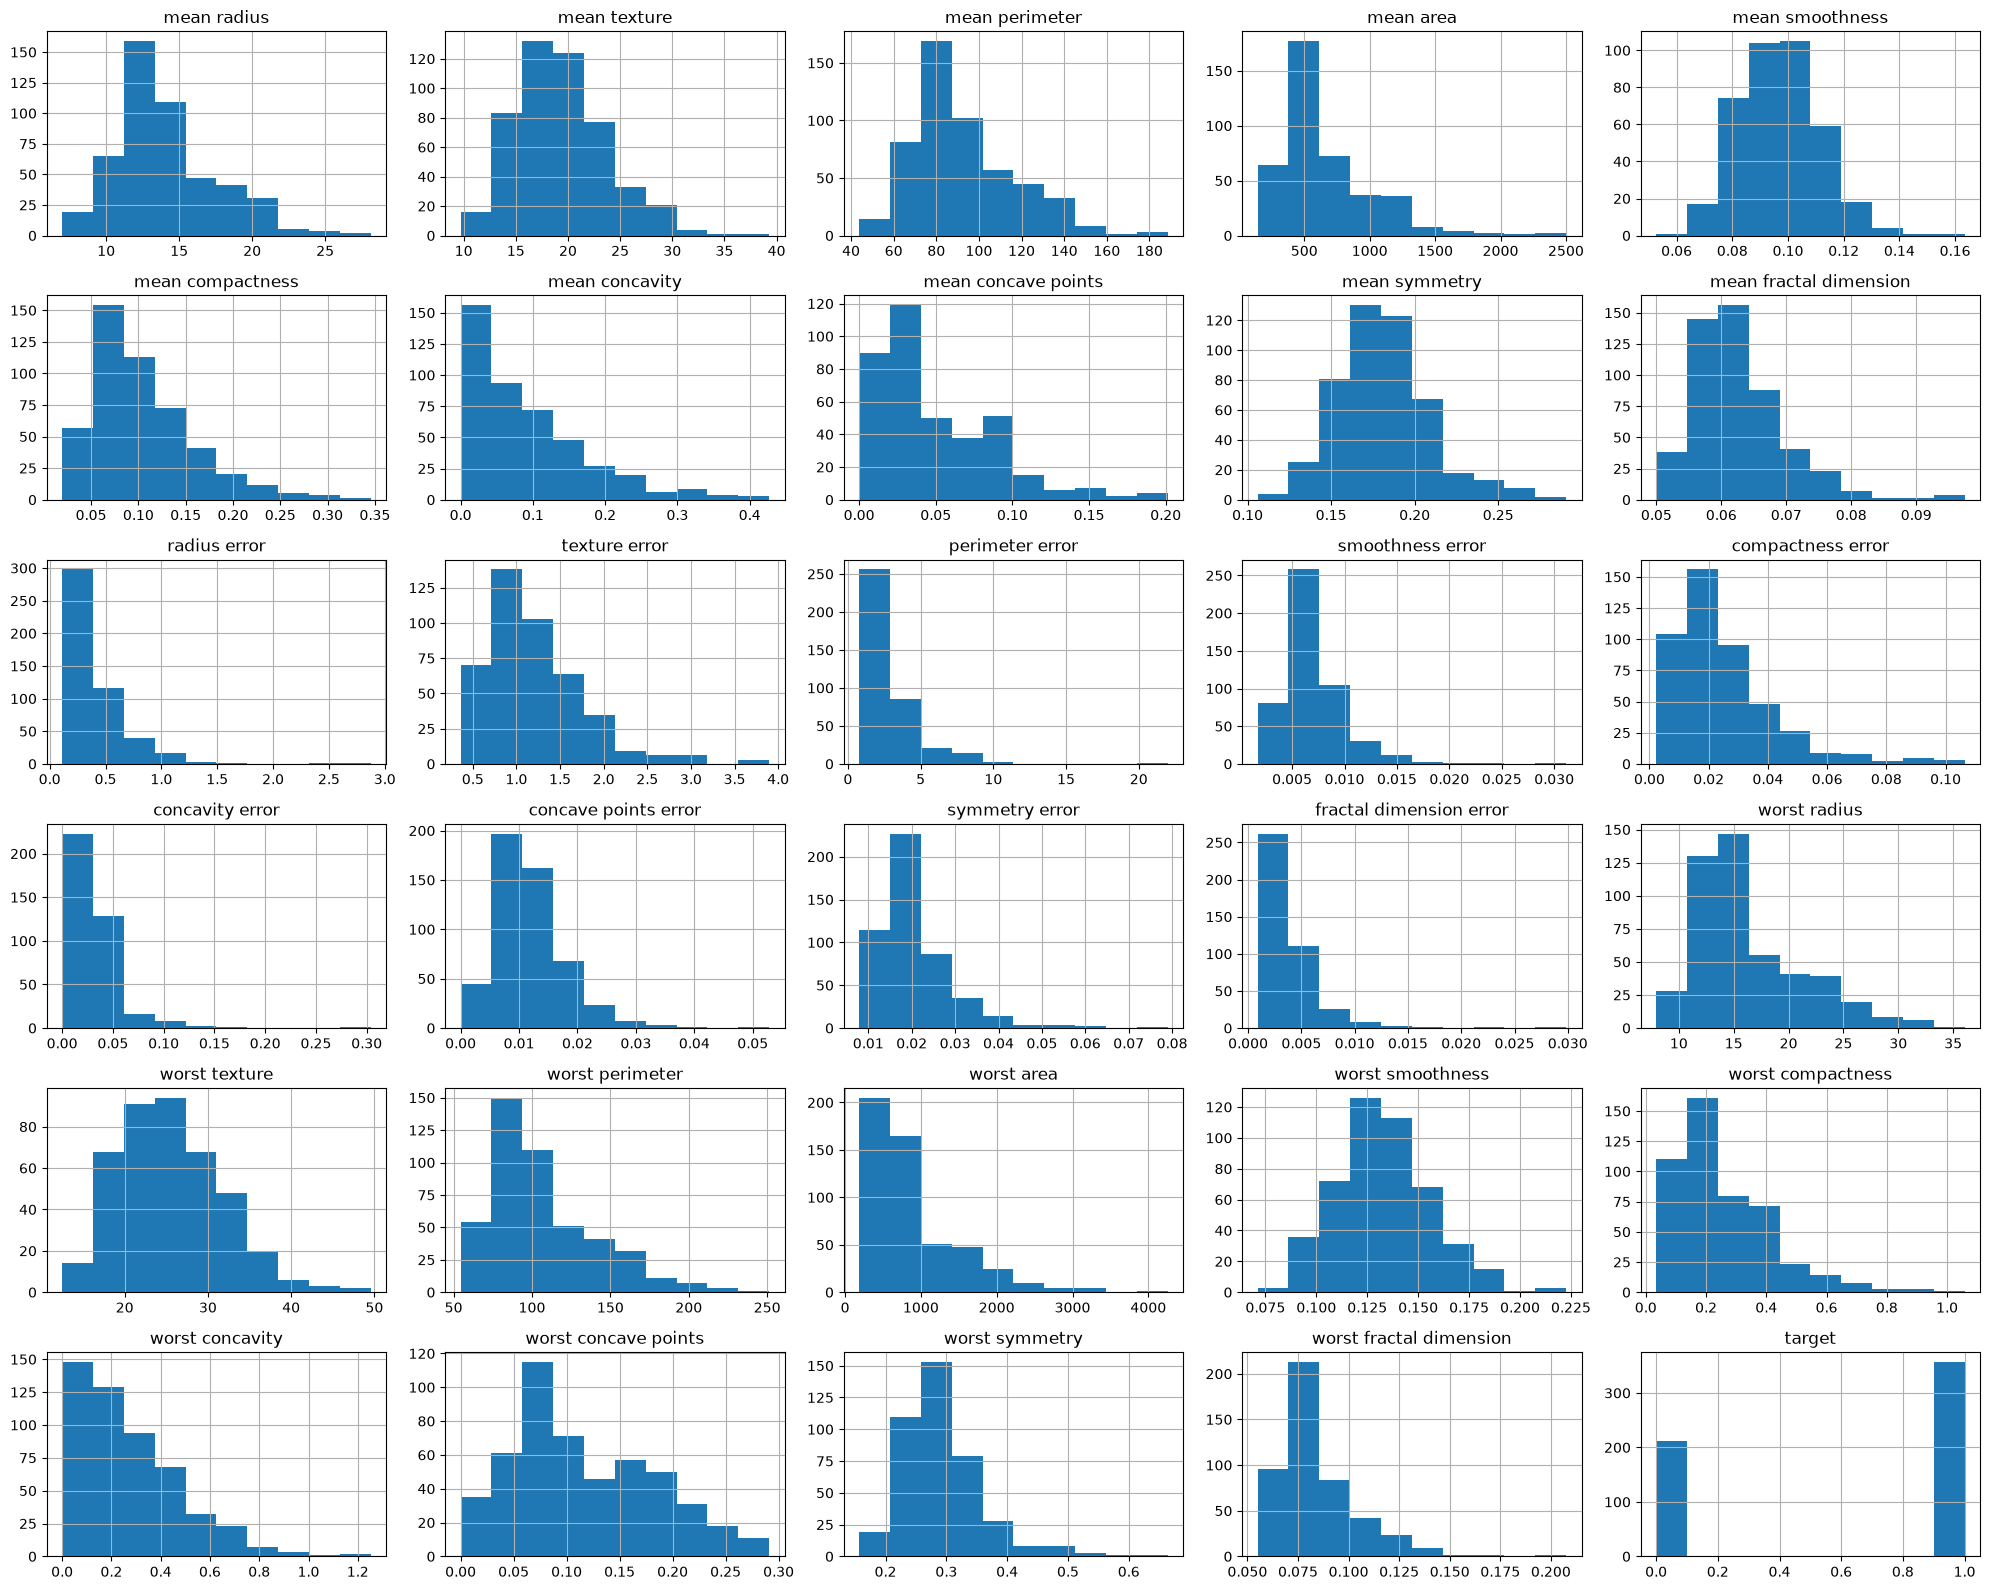

In [5]:
# df.hist() dibuja un histograma por cada columna NUMÉRICA (ignora 'area error', que es texto)
# Los NaN se ignoran automáticamente. figsize = (ancho, alto) en pulgadas
df.hist(figsize=(20, 16))
plt.tight_layout()   # acomoda los títulos para que no se superpongan
plt.show()

✍️ **Preguntas**
1. Nombren **dos variables** que parezcan aproximadamente **simétricas** (forma de campana).
2. Nombren **dos variables** con **cola larga hacia la derecha** (muchos valores bajos y pocos muy altos).
3. ¿Qué pasa con el histograma de `target`? ¿Tiene sentido hacer un histograma de esa variable?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 2) ¿Cuántos bins usar? La regla de Rice

📘 **Concepto.** La cantidad de bins cambia lo que vemos:

- **Muy pocos bins** → vista demasiado general, se pierden detalles (por ejemplo, dos "picos").
- **Demasiados bins** → el gráfico se llena de "ruido": barras que suben y bajan sin un patrón.

Hay reglas para elegir un número razonable. Una muy usada es la **regla de Rice**:

$$k = \lceil 2 \cdot n^{1/3} \rceil$$

donde **n** es la cantidad de observaciones (no nulas) y $\lceil \; \rceil$ significa *redondear hacia arriba*.

🧩 **Regla de Rice**

In [6]:
n = df["mean radius"].notna().sum()          # cantidad de valores NO nulos
bins_rice = int(np.ceil(2 * n ** (1/3)))      # np.ceil = redondear hacia arriba
print("n =", n, "→ bins según Rice:", bins_rice)

n = 482 → bins según Rice: 16


💻 Comparamos la **misma variable** con 5 bins, con Rice y con 100 bins:

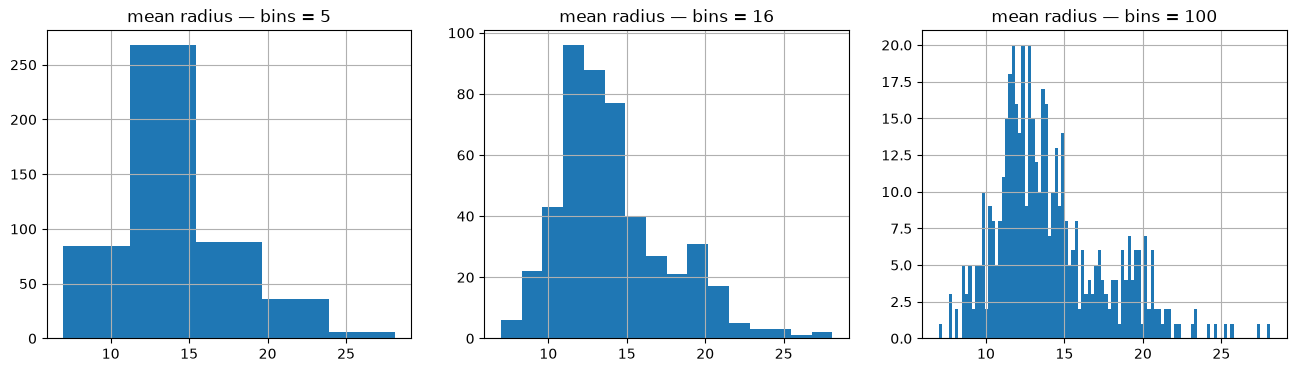

In [7]:
# plt.subplots(1, 3) crea una figura con 3 gráficos en una fila; 'axes' es la lista de esos 3 gráficos
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, b in zip(axes, [5, bins_rice, 100]):
    df["mean radius"].hist(bins=b, ax=ax)
    ax.set_title(f"mean radius — bins = {b}")
plt.show()

# Atajo: pandas acepta directamente bins="rice" y hace el cálculo solo
#df["mean radius"].hist(bins="rice")

💻 Lo mismo para las **primeras 4 variables**: primero con 20 bins y después con la regla de Rice.

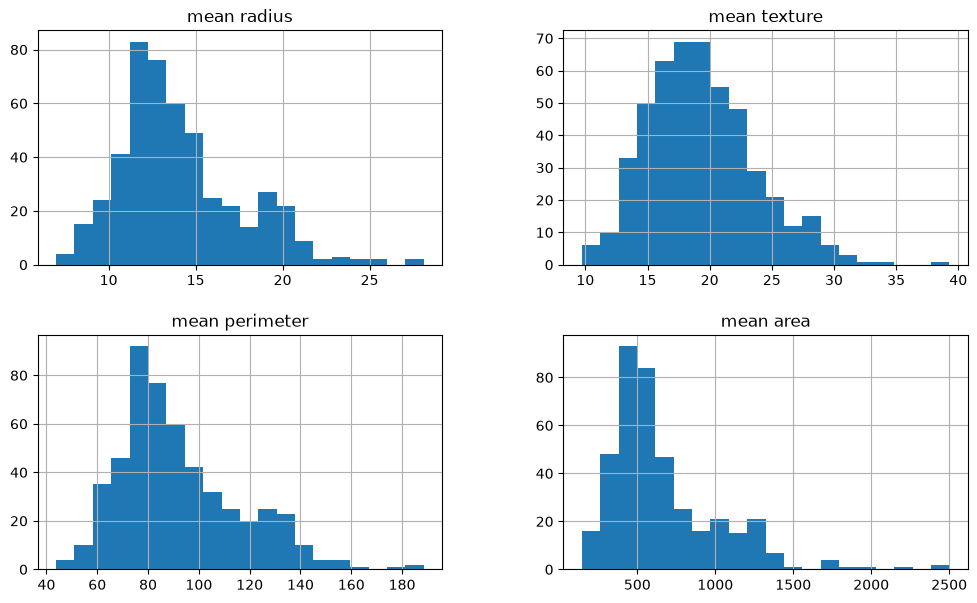

In [8]:
#Podemos manipular el número de bins
df.iloc[:,0:4].hist(bins=20, figsize=(12, 7))  #Se ejecutan ignorando los missing val.
plt.show()

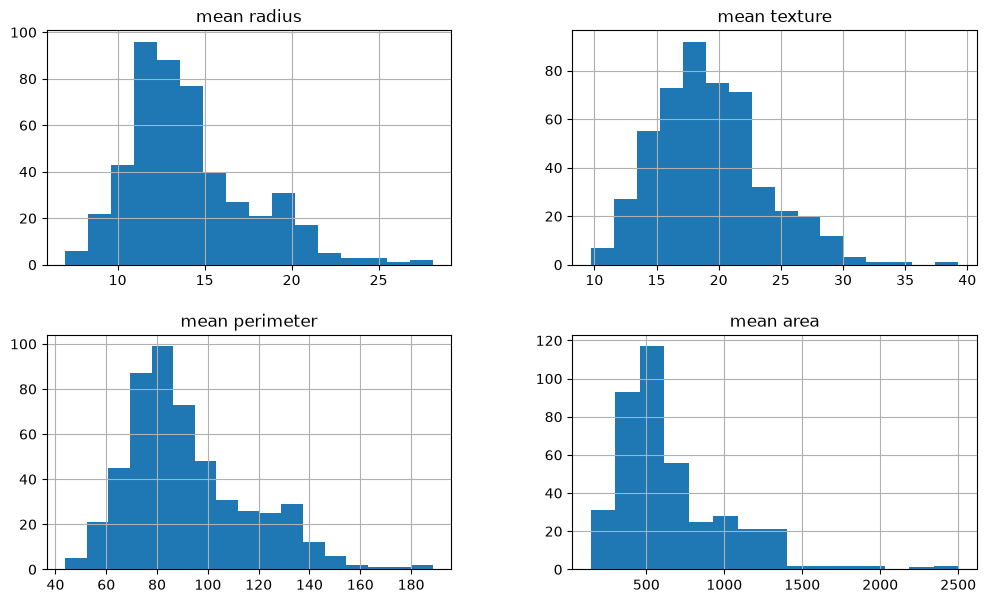

In [9]:
df.iloc[:,0:4].hist(bins="rice", figsize=(12, 7))
plt.show()

✍️ **Pregunta:** ¿Qué se pierde con 5 bins? ¿Qué problema aparece con 100? ¿Cuál de los tres gráficos les sirve más para describir la variable?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 3) Media, mediana y asimetría

📘 **Concepto** (lámina *"Distribuciones simétricas y asimétricas"*):

| Forma | Relación entre medidas | Ejemplo |
|---|---|---|
| **Simétrica** | media ≈ mediana | altura de personas |
| **Asimetría positiva** (cola a la derecha) | **media > mediana** | ingresos, precios de propiedades |
| **Asimetría negativa** (cola a la izquierda) | **media < mediana** | puntajes con tope |

¿Por qué? La **media se "deja arrastrar"** por los valores extremos; la **mediana no**. Por eso, en distribuciones asimétricas, la **mediana suele representar mejor el valor típico**.

pandas también calcula un número que resume la asimetría: **`.skew()`** (coeficiente de asimetría).
- ≈ 0 → simétrica (regla práctica: entre -0,5 y 0,5)
- > 0 → cola a la derecha
- < 0 → cola a la izquierda

💻 Definimos una **función** para reutilizar: dibuja el histograma con la media y la mediana marcadas.

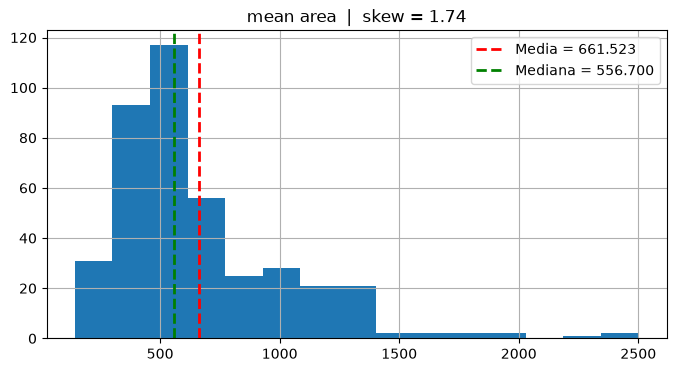

In [10]:
def hist_media_mediana(var):
    """Histograma de 'var' con líneas verticales en la media y la mediana."""
    media = df[var].mean()
    mediana = df[var].median()
    ax = df[var].hist(bins="rice", figsize=(8, 4))
    ax.axvline(media, color="red", linestyle="--", linewidth=2, label=f"Media = {media:.3f}")
    ax.axvline(mediana, color="green", linestyle="--", linewidth=2, label=f"Mediana = {mediana:.3f}")
    ax.set_title(f"{var}  |  skew = {df[var].skew():.2f}")
    ax.legend()
    plt.show()

hist_media_mediana("mean area")

✍️ **Pregunta:** ¿Qué tipo de distribución tiene `mean area`? ¿Qué medida usarían para describir el área "típica" de una muestra y por qué?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

⭐ **Extra:** ranking de las variables más y menos asimétricas.

In [11]:
asimetria = df.skew(numeric_only=True).sort_values(ascending=False)
asimetria

fractal dimension error    3.988005
concavity error            3.923566
perimeter error            3.578511
radius error               3.378242
smoothness error           2.343724
symmetry error             2.191448
worst area                 1.806205
compactness error          1.804073
mean area                  1.743003
worst fractal dimension    1.721105
worst symmetry             1.484707
concave points error       1.441243
worst compactness          1.431309
texture error              1.392157
mean concavity             1.374523
mean fractal dimension     1.373513
mean compactness           1.254714
mean concave points        1.211371
worst concavity            1.184726
worst perimeter            1.164586
worst radius               1.128959
mean radius                0.928228
mean perimeter             0.905293
mean texture               0.663933
mean symmetry              0.632637
worst texture              0.616352
worst concave points       0.476646
mean smoothness            0

## 4) Bins personalizados

📘 A veces queremos **elegir nosotros los cortes** (por ejemplo, para reportar "cuántas muestras tienen radio entre 10 y 12").
En ese caso le pasamos a `bins` una **lista con los bordes** de cada intervalo.

> **Ojo:** los valores que quedan **fuera** del primer y último borde **no se dibujan**. Por eso conviene que los bordes cubran todo el rango (del mínimo al máximo).

Mínimo: 6.981 | Máximo: 28.11


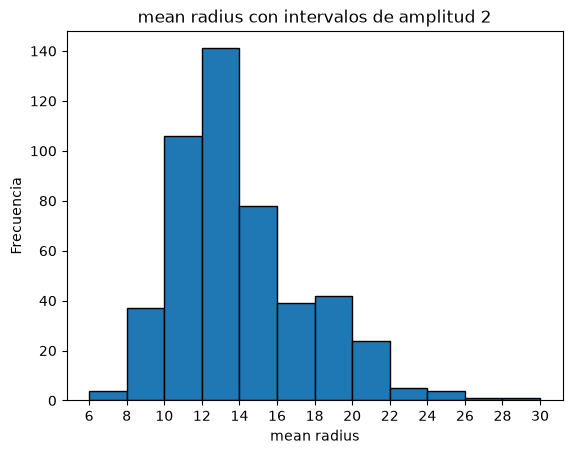

In [12]:
print("Mínimo:", df["mean radius"].min(), "| Máximo:", df["mean radius"].max())

bordes = list(range(6, 32, 2))   # 6, 8, 10, ..., 30 → intervalos de amplitud 2
plt.hist(df["mean radius"].dropna(), bins=bordes, edgecolor="black")   # plt.hist no acepta NaN: usamos dropna()
plt.xticks(bordes)
plt.title("mean radius con intervalos de amplitud 2")
plt.xlabel("mean radius"); plt.ylabel("Frecuencia")
plt.show()

✍️ **Pregunta:** ¿En qué intervalo se concentra la mayor cantidad de muestras? ¿A partir de qué valor las barras se vuelven muy bajas?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 5) ¿Y las variables categóricas? Gráfico de barras

📘 **Concepto** (lámina *"Clasificación de variables"*): el histograma es para variables **numéricas**. Para variables **categóricas** usamos un **gráfico de barras** construido a partir de la **tabla de frecuencias** (`value_counts()`): una barra por categoría, separadas entre sí.

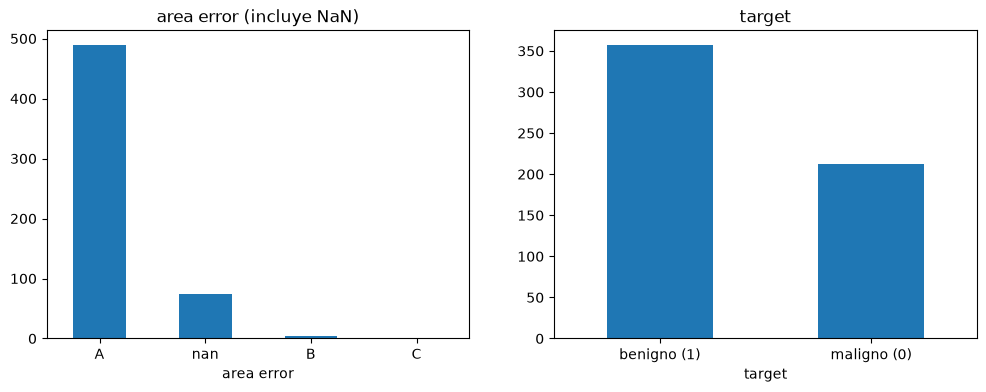

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["area error"].value_counts(dropna=False).plot(kind="bar", ax=axes[0], title="area error (incluye NaN)")
df["target"].value_counts().rename({0: "maligno (0)", 1: "benigno (1)"}).plot(kind="bar", ax=axes[1], title="target")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.show()

✍️ **Pregunta:** ¿Por qué acá usamos barras y no un histograma? ¿Qué nos dice el gráfico de `target` sobre el **balance de clases**?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_

## 6) Volvamos a la pregunta guía: ¿la distribución cambia según el diagnóstico?

💻 Superponemos dos histogramas de la misma variable: uno para los casos **malignos** y otro para los **benignos**. `alpha` hace las barras semitransparentes para poder ver las dos.

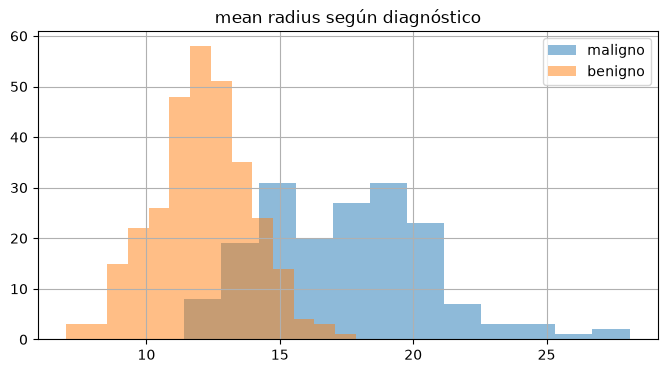

In [14]:
def hist_por_diagnostico(var):
    for valor, etiqueta in [(0, "maligno"), (1, "benigno")]:
        df.loc[df["target"] == valor, var].hist(bins="rice", alpha=0.5, label=etiqueta, figsize=(8, 4))
    plt.title(f"{var} según diagnóstico")
    plt.legend()
    plt.show()

hist_por_diagnostico("mean radius")

🧩 Prueben con **otra variable**: una que crean que diferencia bien y otra que crean que no (por ejemplo `"mean smoothness"`, `"worst concave points"`, `"mean texture"`, `"mean fractal dimension"`).

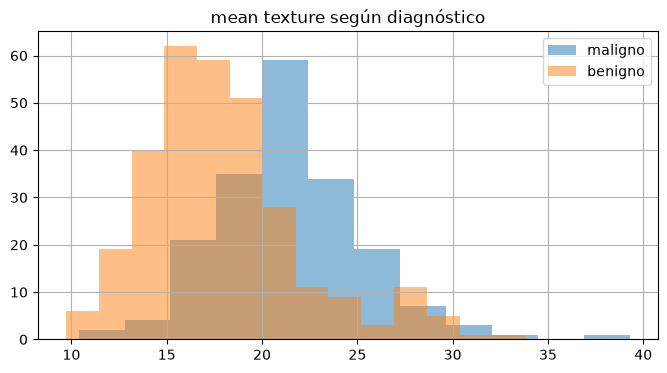

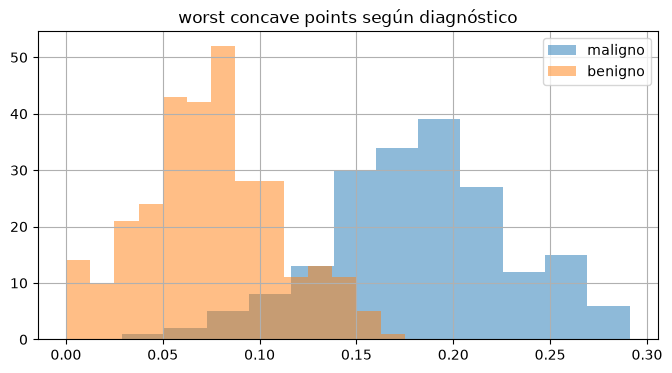

In [16]:
hist_por_diagnostico("mean texture")
hist_por_diagnostico("worst concave points")

✍️ **Pregunta:** ¿En qué variable los dos histogramas están **más separados**? ¿En cuál se **superponen** casi por completo? ¿Qué significa eso para la pregunta guía?

✍️ **Respuesta del equipo:**

_(Doble clic acá para escribir la respuesta.)_